# Milestone 10 - Evaluation scorecard (RAGAS)

Runs the **guardrailed pipeline** and the **naive-RAG baseline** (dense top-5, no reranking, no verification, same generator and prompt) over the 200 held-out QA pairs plus 20 deliberately unanswerable questions, then scores them with (a) label-based metrics - RAGAS context precision / recall against the gold page, answer correctness, citation accuracy, latency - and (b) the **RAGAS framework** itself (faithfulness, answer relevancy, LLM context precision / recall) using an independent local judge, Qwen2.5-7B-Instruct served by llama.cpp. Full audit logs are written for every query.

In [1]:
import os, sys, json, time, warnings, pathlib
warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
from rag import config

In [2]:
from rag import evaluation, generator, store
from rag.corpus import load_jsonl
from rag.pipeline import RAGPipeline
store.ensure_qdrant(); generator.ensure_llm()
test = load_jsonl(config.EVAL_DIR / "test_qa.jsonl"); unans = load_jsonl(config.EVAL_DIR / "unanswerable_qa.jsonl")
OUT = config.ARTIFACT_DIR / "eval"; OUT.mkdir(exist_ok=True)
RECOMPUTE = not (OUT / "full_test.jsonl").exists()
print("recompute:", RECOMPUTE)

recompute: False


In [3]:
if RECOMPUTE:
    pipe = RAGPipeline()
    print("reranker:", pipe.reranker_name)
    t = time.time()
    full = evaluation.run_queries(pipe, test, "full", OUT / "full_test.jsonl")
    naive = evaluation.run_queries(pipe, test, "naive", OUT / "naive_test.jsonl")
    full_u = evaluation.run_queries(pipe, unans, "full", OUT / "full_unanswerable.jsonl", log_every=0)
    naive_u = evaluation.run_queries(pipe, unans, "naive", OUT / "naive_unanswerable.jsonl", log_every=0)
    print(f"generation runs finished in {(time.time() - t)/60:.1f} min")
else:
    full, naive, full_u, naive_u = (load_jsonl(OUT / f) for f in ("full_test.jsonl", "naive_test.jsonl", "full_unanswerable.jsonl", "naive_unanswerable.jsonl"))

### Label-based scorecard

In [4]:
sf, sn = evaluation.score_records(full), evaluation.score_records(naive)
uf, un = evaluation.score_unanswerable(full_u), evaluation.score_unanswerable(naive_u)
keys = ["context_precision", "context_recall", "answered", "correct", "correct_strict", "wrong_answer", "citation_accuracy", "citation_precision",
        "nli_faithfulness", "regenerated", "latency_mean", "latency_p50", "latency_p95", "within_3_5s"]
tbl = pd.DataFrame({"naive RAG baseline": {k: sn[k] for k in keys}, "guardrailed pipeline": {k: sf[k] for k in keys}})
tbl.loc["unanswerable: correct refusal"] = [un["correct_refusal_rate"], uf["correct_refusal_rate"]]
tbl.round(3)

,naive RAG baseline,guardrailed pipeline
context_precision,0.793,0.991
context_recall,0.940,0.995
answered,0.945,0.990
correct,0.920,0.980
correct_strict,0.905,0.955
wrong_answer,0.025,0.010
citation_accuracy,0.968,0.995
citation_precision,0.953,0.990
nli_faithfulness,NaN,1.000
regenerated,0.000,0.010


In [5]:
print("status counts  full :", sf["status_counts"]); print("status counts  naive:", sn["status_counts"])
print("\nnaive baseline hallucinated on unanswerable questions:"); [print("  ", h) for h in un["hallucinated_answers"]]
print("\nguardrailed pipeline hallucinated on unanswerable questions:"); [print("  ", h) for h in uf["hallucinated_answers"]]

status counts  full : {'verified': 198, 'abstained': 2}
status counts  naive: {'unverified_baseline': 189, 'abstained': 11}

naive baseline hallucinated on unanswerable questions:

guardrailed pipeline hallucinated on unanswerable questions:


[]

### RAGAS framework scores (independent judge: Qwen2.5-7B-Instruct)
All four RAGAS metrics - faithfulness, answer relevancy, LLM context precision (with reference) and LLM context recall - scored by the judge model.

In [6]:
RAGAS_FILE = OUT / "ragas.json"
if RECOMPUTE or not RAGAS_FILE.exists():
    t = time.time()
    ALL = ("faithfulness", "answer_relevancy", "context_precision", "context_recall")
    rf, rf_rows = evaluation.ragas_scores(full, ALL)
    rn, rn_rows = evaluation.ragas_scores(naive, ALL)
    RAGAS_FILE.write_text(json.dumps({"full": rf, "naive": rn, "full_rows": rf_rows, "naive_rows": rn_rows}, indent=2, default=float))
    print(f"RAGAS finished in {(time.time() - t)/60:.1f} min")
rg = json.loads(RAGAS_FILE.read_text())
gv = json.loads((OUT / "ragas_generator_view.json").read_text())
ragas_tbl = pd.DataFrame({"naive RAG baseline": {k: v for k, v in rg["naive"].items() if isinstance(v, float)},
                          "guardrailed pipeline": {k: v for k, v in rg["full"].items() if isinstance(v, float)}})
ragas_tbl.loc["faithfulness (judge sees generator input)"] = [gv["naive"]["means"]["faithfulness"], gv["full"]["means"]["faithfulness"]]
print("judge failures (NaN rate):", rg["full"]["nan_rate"], "| scored answers:", rg["full"]["n_scored"], "/", rg["naive"]["n_scored"])
ragas_tbl.round(3)

judge failures (NaN rate): {'faithfulness': 0.0, 'answer_relevancy': 0.0, 'llm_context_precision_with_reference': 0.0, 'context_recall': 0.0} | scored answers: 198 / 189


,naive RAG baseline,guardrailed pipeline
faithfulness,0.854,0.891
answer_relevancy,0.933,0.940
llm_context_precision_with_reference,0.832,0.990
context_recall,0.995,1.000
faithfulness (judge sees generator input),0.971,0.997


### What the faithfulness judge is shown
The generator receives each source with a header such as `(document: CU4_Controller_Firmware_Release_Notes.docx, p. 3)`. In the first RAGAS runs the judge received only the page text and the answer with `[Source n]` markers, so a correct answer mentioning an entity that appears only in the document name (e.g. *CU-4*) was marked unsupported, and citation markers were treated as claims. The corrected judge view shows the judge exactly the generator's input (header + text) and the answer without citation markers. The change was validated on 60 **development** questions (facts disjoint from the test set) before being applied to the test set; both views are reported.

In [7]:
dev = json.loads((config.ARTIFACT_DIR / "dev_judge_view.json").read_text())
display(pd.DataFrame(dev).T.rename(index={"raw": "page text + [Source n] (old)", "generator": "exactly the generator input (new)"}))
views = pd.DataFrame({"page text + [Source n] (old)": {"naive": rg["naive"]["faithfulness"], "pipeline": rg["full"]["faithfulness"]},
                      "generator input (new)": {"naive": gv["naive"]["means"]["faithfulness"], "pipeline": gv["full"]["means"]["faithfulness"],
                                                "pipeline + LoRA": gv["lora"]["means"]["faithfulness"]}})
views.round(3)

,faithfulness,below_1,n
page text + [Source n] (old),0.965517,4.0,58.0
exactly the generator input (new),1.000000,0.0,58.0


,page text + [Source n] (old),generator input (new)
naive,0.854,0.971
pipeline,0.891,0.997
pipeline + LoRA,NaN,0.997


In [8]:
by = {r["qid"]: r for r in full}
low = [x for x in gv["full"]["rows"] if x["faithfulness"] < 1]
print(len(low), "pipeline answers still scored below 1.0 by the judge (generator view):")
pd.DataFrame([{"faithfulness": x["faithfulness"], "answer": by[x["qid"]]["answer_raw"][:110], "gold": by[x["qid"]]["gold_answer"],
               "correct": evaluation.answer_correct(by[x["qid"]])} for x in low])

1 pipeline answers still scored below 1.0 by the judge (generator view):


,faithfulness,answer,gold,correct
0,0.5,"Tampere Works had a 98.3% on-time delivery rate for FY2025, indicating a high level of reliability in shipping",98.3%,1.0


### Stretch goal: LoRA fine-tune of Phi-4-mini
LoRA (r = 16, alpha = 32, attention + MLP projections, 23 M trainable parameters = 0.6%) trained for one epoch on 806 grounded, cited examples built with the production retrieval pipeline from training facts only (no test or development facts), including 20 abstention examples; merged, converted to GGUF and quantised to Q8_0 exactly like the base model, then evaluated on the same 200 test questions with the same retrieval, reranker, prompt and guardrail.

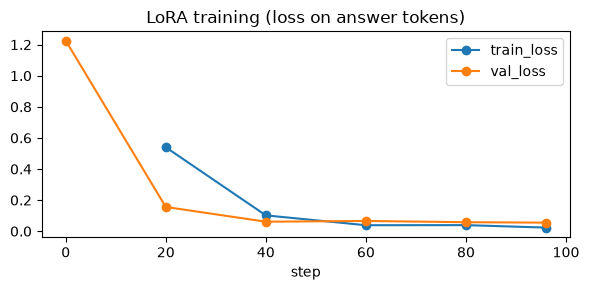

,base Phi-4-mini,LoRA Phi-4-mini
answered,0.990,0.995
correct,0.980,0.995
correct_strict,0.955,0.980
wrong_answer,0.010,0.000
citation_accuracy,0.995,1.000
citation_precision,0.990,1.000
nli_faithfulness,1.000,1.000
regenerated,0.010,0.000
latency_p50,0.826,0.865
latency_p95,2.320,1.979


In [9]:
lora_dir = config.ARTIFACT_DIR / "eval_lora"
lora, lora_u = load_jsonl(lora_dir / "full_test.jsonl"), load_jsonl(lora_dir / "full_unanswerable.jsonl")
sl, ul = evaluation.score_records(lora), evaluation.score_unanswerable(lora_u)
cmp_keys = ["answered", "correct", "correct_strict", "wrong_answer", "citation_accuracy", "citation_precision", "nli_faithfulness", "regenerated", "latency_p50", "latency_p95"]
lt = pd.DataFrame({"base Phi-4-mini": {k: sf[k] for k in cmp_keys}, "LoRA Phi-4-mini": {k: sl[k] for k in cmp_keys}})
lt.loc["unanswerable: correct refusal"] = [uf["correct_refusal_rate"], ul["correct_refusal_rate"]]
lt.loc["RAGAS faithfulness (generator view)"] = [gv["full"]["means"]["faithfulness"], gv["lora"]["means"]["faithfulness"]]
lt.loc["RAGAS answer relevancy"] = [rg["full"]["answer_relevancy"], gv["lora"]["means"]["answer_relevancy"]]
lh = json.loads((config.MODEL_DIR / "phi4-mini-lora-adapter" / "training_history.json").read_text())
fig, ax = plt.subplots(figsize=(6, 3)); pd.DataFrame({k: lh[k] for k in ("step", "train_loss", "val_loss")}).plot(x="step", ax=ax, marker="o")
ax.set_title("LoRA training (loss on answer tokens)"); plt.tight_layout(); plt.savefig(config.ARTIFACT_DIR / "lora_training_curve.png", dpi=120); plt.show()
lt.round(3)

### Scorecard against the proposal's targets

The **final system** uses the LoRA-tuned generator. Retrieval and reranking are identical for both generators, so context metrics are shared; generator-dependent metrics are measured separately.

In [10]:
rel = lambda run, fallback: gv[run]["means"].get("answer_relevancy", fallback)
rows = [
    ("Context precision (RAGAS def., gold-page labels)", ">= 0.90", sn["context_precision"], sf["context_precision"], sl["context_precision"]),
    ("Context precision (RAGAS, LLM judge)", ">= 0.90", rg["naive"]["llm_context_precision_with_reference"], rg["full"]["llm_context_precision_with_reference"], rg["full"]["llm_context_precision_with_reference"]),
    ("Context recall (RAGAS, LLM judge)", "-", rg["naive"]["context_recall"], rg["full"]["context_recall"], rg["full"]["context_recall"]),
    ("Faithfulness (RAGAS, judge sees generator input)", ">= 0.95", gv["naive"]["means"]["faithfulness"], gv["full"]["means"]["faithfulness"], gv["lora"]["means"]["faithfulness"]),
    ("Faithfulness (RAGAS, page-text-only judge view)", "(info)", rg["naive"]["faithfulness"], rg["full"]["faithfulness"], None),
    ("Answer relevancy (RAGAS)", "-", rg["naive"]["answer_relevancy"], rel("full", rg["full"]["answer_relevancy"]), rel("lora", None)),
    ("Citation accuracy (gold page cited)", ">= 0.95", sn["citation_accuracy"], sf["citation_accuracy"], sl["citation_accuracy"]),
    ("End-to-end latency p95 (s)", "< 3.5", sn["latency_p95"], sf["latency_p95"], sl["latency_p95"]),
    ("Answer correctness (semantic match)", "-", sn["correct"], sf["correct"], sl["correct"]),
    ("Answer correctness (strict exact match)", "-", sn["correct_strict"], sf["correct_strict"], sl["correct_strict"]),
    ("Wrong answers delivered", "-", sn["wrong_answer"], sf["wrong_answer"], sl["wrong_answer"]),
    ("Refusal on unanswerable questions", "-", un["correct_refusal_rate"], uf["correct_refusal_rate"], ul["correct_refusal_rate"]),
]
score = pd.DataFrame(rows, columns=["metric", "target", "naive", "pipeline (base)", "final system (LoRA)"])
def passed(r):
    v = r["final system (LoRA)"]
    if r["target"].startswith(">="): return v >= float(r["target"][3:])
    if r["target"].startswith("<"): return v < float(r["target"][2:])
    return None
score["target met (final)"] = score.apply(passed, axis=1)
score = score.round(3)
(config.ARTIFACT_DIR / "scorecard.json").write_text(score.to_json(orient="records", indent=2))
score

,metric,target,naive,pipeline (base),final system (LoRA),target met (final)
0,"Context precision (RAGAS def., gold-page labels)",>= 0.90,0.793,0.991,0.991,True
1,"Context precision (RAGAS, LLM judge)",>= 0.90,0.832,0.990,0.990,True
2,"Context recall (RAGAS, LLM judge)",-,0.995,1.000,1.000,None
3,"Faithfulness (RAGAS, judge sees generator input)",>= 0.95,0.971,0.997,0.997,True
4,"Faithfulness (RAGAS, page-text-only judge view)",(info),0.854,0.891,NaN,None
5,Answer relevancy (RAGAS),-,0.933,0.950,0.871,None
6,Citation accuracy (gold page cited),>= 0.95,0.968,0.995,1.000,True
7,End-to-end latency p95 (s),< 3.5,1.160,2.320,1.979,True
8,Answer correctness (semantic match),-,0.920,0.980,0.995,None
9,Answer correctness (strict exact match),-,0.905,0.955,0.980,None


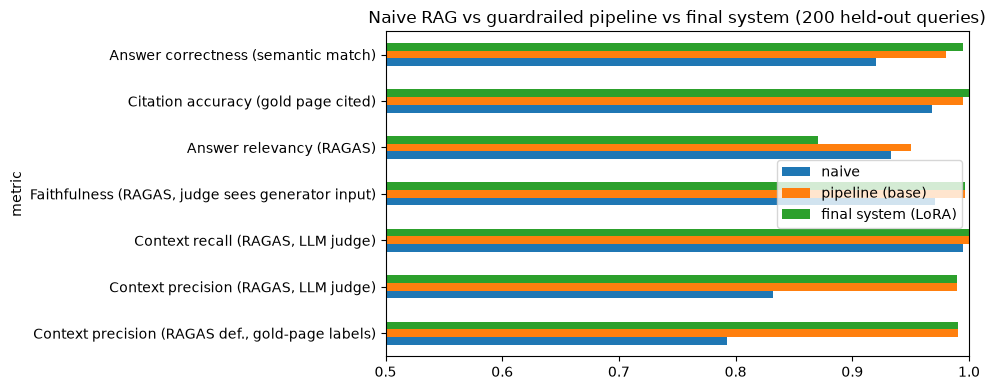

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
plot = score[score.metric.str.contains("precision|recall|Faithfulness \(RAGAS, judge|relevancy|Citation|correctness \(semantic")].set_index("metric")[["naive", "pipeline (base)", "final system (LoRA)"]]
plot.plot.barh(ax=ax); ax.set_xlim(0.5, 1.0); ax.set_title("Naive RAG vs guardrailed pipeline vs final system (200 held-out queries)")
plt.tight_layout(); plt.savefig(config.ARTIFACT_DIR / "scorecard.png", dpi=120); plt.show()

### Effect of the two post-analysis bug fixes
After the first evaluation run, error analysis found two generic bugs: (1) the reranker cutoff could empty the context entirely, and (2) NLI premises lacked the document title, so entities named only in the title (e.g. *CU-4*) could not be entailed. Both were fixed (best passage always kept; premises prefixed with `title | section`). Because the fixes came from test-set errors, the pre-fix run is kept in `artifacts/eval_v1_before_fixes/` and reported here for transparency.

In [12]:
pre = config.ARTIFACT_DIR / "eval_v1_before_fixes" / "full_test.jsonl"
if pre.exists():
    s0 = evaluation.score_records(load_jsonl(pre))
    display(pd.DataFrame({"before fixes": {k: s0[k] for k in keys}, "after fixes": {k: sf[k] for k in keys}}).round(3))

,before fixes,after fixes
context_precision,0.980,0.991
context_recall,0.980,0.995
answered,0.950,0.990
correct,0.940,0.980
correct_strict,0.920,0.955
wrong_answer,0.010,0.010
citation_accuracy,0.995,0.995
citation_precision,0.982,0.990
nli_faithfulness,1.000,1.000
regenerated,0.030,0.010


### Breakdown by document type and latency profile

In [13]:
df = pd.DataFrame([{**{k: r[k] for k in ("doc_type", "status")}, "correct": evaluation.answer_correct(r),
                    **{f"t_{k}": v for k, v in r["timings_s"].items()}} for r in full])
display(df.groupby("doc_type").agg(n=("correct", "size"), correct=("correct", "mean"), mean_latency=("t_total", "mean")).round(3))
df[[c for c in df.columns if c.startswith("t_")]].describe(percentiles=[.5, .95]).round(3)

,n,correct,mean_latency
doc_type,,,
csv,48,0.979,0.866
docx,44,1.000,0.820
md,36,0.944,1.034
pdf,72,0.986,1.212


,t_retrieval,t_rerank,t_generation,t_verification,t_total
count,200.000,200.000,200.000,200.000,200.000
mean,0.030,0.492,0.354,0.134,1.011
std,0.025,0.228,0.280,0.251,0.555
min,0.016,0.206,0.174,0.000,0.482
50%,0.021,0.358,0.304,0.055,0.826
95%,0.071,0.907,0.604,1.024,2.320
max,0.302,0.980,3.278,1.250,3.855


### Audit log sample
Every query writes retrieved chunk IDs, dense / sparse / RRF / rerank scores and per-claim verifier verdicts.

In [14]:
log = sorted(config.AUDIT_DIR.glob("audit_*.jsonl"))[-1]
lines = log.read_text().splitlines()
print(log.name, "-", len(lines), "audit records")
rec = json.loads(next(l for l in reversed(lines) if '"mode": "full"' in l))
print(json.dumps(rec, indent=1)[:2500])

audit_20261014.jsonl - 1330 audit records
{
 "ts": "2026-10-14T04:39:11.280529+00:00",
 "query_id": "5d4f43d2ab97",
 "question": "What is the hotel cap per night outside capital cities?",
 "mode": "full",
 "status": "verified",
 "answer": "Hotel accommodation is capped at EUR 210 per night outside capital cities [HIS_Employee_Handbook_2026.pdf, p. 4].",
 "citations": [
  {
   "source": 1,
   "doc": "HIS_Employee_Handbook_2026.pdf",
   "page": 4,
   "loc": "p. 4"
  }
 ],
 "retrieved": [
  {
   "chunk_id": "HIS_Employee_Handbook_2026.pdf::4::0",
   "doc": "HIS_Employee_Handbook_2026.pdf",
   "page": 4,
   "dense_rank": 1,
   "sparse_rank": 1,
   "dense_score": 0.5562541,
   "sparse_score": 0.10834435,
   "rrf_score": 0.03278688524590164,
   "rerank_score": 8.074896812438965
  }
 ],
 "regenerations": 0,
 "timings_s": {
  "retrieval": 0.01986787499845377,
  "rerank": 0.3166278749995399,
  "generation": 0.30641758300043875,
  "verification": 0.07673929199881968,
  "total": 0.719670040998607

### Remaining errors of the guardrailed pipeline

In [15]:
errs = [{"question": r["question"], "gold": r["gold_answer"], "status": r["status"], "answer": r["answer"][:160]}
        for r in full if not evaluation.answer_correct(r)]
print(len(errs), "queries not answered correctly")
pd.DataFrame(errs)

4 queries not answered correctly


,question,gold,status,answer
0,Who is the ISO 9001 registrar?,Nordic Assurance Services,abstained,I cannot verify an answer to this question from the available documents.
1,What is the last service date of AST-2203?,2026-05-15,verified,"The last service date of AST-2203 is 2026-05-11 [maintenance_work_orders_2026.csv, row 30]."
2,How many people attended the engineering meeting on design review cadence?,12,verified,"Twelve people attended the engineering meeting on design review cadence [engineering_meeting_notes.md, section 6]."
3,What known issue affects CU-4 firmware 4.2?,display freezes after 49 days of uptime,abstained,I cannot verify an answer to this question from the available documents.
